딥러닝 파이토치 교과서
ch4. (pg.138~163)

# 4.1 인공 신경망의 한계와 딥러닝 출현

오늘날 인공 신경망에서 이용하는 구조 (입력층, 출력층, 가중치로 구성된 구조)는 퍼셉트론이라는 선형 분류기이다.

퍼셉트론은 다수의 신호를 입력으로 받아 하나의 신호를 출력한다. 이 신호를 입력으로 받아 '흐른다/안 흐른다'는 정보를 앞을 전달하는 원리로 작동한다.

**AND 게이트**

AND 게이트는 모든 입력이 1일때 작동한다. 즉, 이볅 중 어떤 하나라도 0을 가지면 작동을 멈춘다.


**OR 게이트**

OR 게이트는 입력에서 둘 중 하나만 1이거나 둘다 1일 때 작동한다. 즉, 입력 모두가 0을 갖는 경우를 제외한 나머지가 모두 1값을 갖는다.

**XOR 게이트**

배타적 논리합이라는 용어로 입력 두개 중 한 개만 1일 때 작동하는 논리 연산이다.

XOR 게이트는 데이터가 비선형적으로 분리되기 때문에 제대로 된 분류가 어렵다. 즉, 단층 퍼셉트론에서는 AND,OR 연산에 대해서는 학습이 가능하지만, XOR에 대해서는 학습이 불가능하다.


이를 극복하는 방안으로 입력층과 출력층 사이에 하나 이상의 은닉층을 두어 비선형적으로 분리되는 데이터에 대해서도 학습이 가능하도록 다층 퍼셉트론을 고안했다.

이때 입력층과 출력층 사이에 은닉층이 여러 개 있는 신경망을 **심층 신경망**이라고 하며 **딥러닝**이라고도 한다.

---
# 4.2 딥러닝 구조

**4.2.1 딥러닝 용어**

딥러닝은 입력층, 출력층과 두 개 이상의 은닉층으로 구성되어 있다.

- 입력층: 데이터를 받아들이는 층
- 은닉층: 모든 입력 노드부터 입력 값을 받아 가중합을 계산하고, 이 값을 활성화 함수에 적용하여 출력층에 전달하는 층
- 출력층: 신경망의 최종 결괏값이 포함된 층


- 가중치: 노드와 노드 간 연결 강도, 입력값이 연산 결과에 미치는 영향력을 조절하는 요소
- 바이어스: 가중합에 더해 주는 상수로 하나의 뉴런에서 활성화 함수를 거쳐 최종적으로 출력되는 값을 조절하는 역할
- 가중합, 전달 함수: 가중치와 신호의 곱을 합한 것
- 활성화 함수: 신호를 입력받아 이를 적절히 처리하여 출력해주는 함수
- 손실함수: 가중치 학습을 윟 출력 함수의 결과와 실제 값 간의 오차를 측정하는 함수

**활성화 함수**

1. 시그모이드 함수
  : 선형 함수의 결과를 0~1 사이에서 비선형 형태로 변형해준다. 주로 로지스틱 회귀와 같은 분류 문제를 확률적으로 표현하는 데 사용됨. 다만 딥러닝 모델의 깊이가 깊어지면 기울기가 사라지는 '기울기 소명 문제'가 발생하여 딥러닝 모델에서는 잘 사용하지 않는다.

2. 하이퍼볼릭 탄젠트 함수
  : 선형 함수의 결과를 -1~1 사이에서 비선형 형태로 변형해준다. 시그모이드에서 결괏값이 평균이 0이 아닌 양수로 편향된 문제를 해결하는 데 사용했으나, 기울기 소멸 문제는 여전히 발생

3. 렐루 함수
  : 입력이 음수일 때는 0을 출력하고 양수일 때는 x를 출력한다. 경사 하강법에 영향을 주지 않아서 학습 속도가 빠르고 기울기 소멸 문제가 발생하지 않는 장점이 있다. 일반적으로 은닉층에서 사용된다.

4. 리키 렐루 함수
   : 입력값이 음수이면 0이 아닌 0.001처럼 매우 작은 수를 반환한다. 입력값이 수렴하는 구간이 제거되어 렐루 함수의 문제를 해결할 수 있다.

5. 소프트맥스 함수
  : 입력값을 0~1사이에 출력되도록 정규화하여 출력 값들의 총 합이 1이 되도록 한다. 보통 딥러닝에서 출력 노드의 활성화 함수로 많이 사용된다.

  $$y_k = \frac{e^{a_k}}{\sum_{i=1}^{n} e^{a_i}}$$

In [1]:
import torch

In [2]:
class Net(torch.nn.Module):
  def __init__(self, n_feature, n_hidden, n_output):
    super(Net, self).__init__()
    self.hidden = torch.nn.Linear(n_feature, n_hidden) #은닉층
    self.relu = torch.nn.ReLu(inplace=True) #활성화 함수
    self.out = torch.nn.Linear(n_hidden, n_output) #출력층
    self.softmax = torch.nn.Softmax(dim=n_output)
  def forward(self, x):
    x = self.hidden(x)
    x = self.relu(x)  #은닉층을 위한 렐루 활성화 함수
    x = self.out(x)
    x = self.softmax(x)  #출력층을 위한 소프트맥스 활성화 함수
    return x

**손실 함수**

경사 하강법에서 미분의 기울기를 이용하여 오차를 비교하고 최소화하는 방향으로 이동시키는 방법이다. 이때 오차를 구하는 방법이 손실함수이다.

1. 평균 제곱 오차
  : 실제 값과 예측 값의 차이를 제곱하여 평균을 낸 것이 평균 제곱 오차이다. 실제 값과 예측값의 차이가 클수록 평균 제곱 오차의 값도 커진다는 것은 반대로 생각하면 이 값이 작을 수록 예측력이 좋다는 뜻이다.

In [3]:
#import torch

#loss_fn = torch.nn.MSELoss(reduction='sum')
#y_pred = model(x)
#loss = loss_fn(y_pred, y)

2. 크로스 엔트로피 오차
  : 분류 문제에서 원-핫 인코딩했을 때 사용할 수 있는 오차 계산법이다.
  두 개의 확률 분포 차이를 이용하기 때문에 시그모이드의 영향을 덜 받는다.

In [4]:
#loss = nn.CrossEntropyLoss()
#input = torch.randn(5,6,requires_grad=True)
#target = torch.empty(5, dtype=torch.long).random_(5)
#output = loss(input, target)
#output.backward()

**4.2.2 딥러닝 학습**

순전파

: 네트워크에 훈련 데이터가 들어올 때 발생하며, 데이터를 기반으로 예측 값을 계산하기 위해 전체 신경망을 교차해 지나간다.

역전파

: 손실 함수 비용이 0에 가깝도록 하기 위해 모델이 훈련을 반복하면서 가중치를 조정

**4.2.3 딥러닝의 문제점과 해결 방안**
1. 과적합 문제 발생


In [5]:
class DropoutModel(torch.nn.Module):
  def __init__(self):
    super(DropoutModel, self).__init__()
    self.layer1 = torch.nn.Linear(784, 1200)
    self.dropout1 = torch.nn.Dropout(p=0.5)
    self.layer2 = torch.nn.Linear(1200,1200)
    self.dropout2 = torch.nn.Dropout(p=0.5)
    self.layer3 = torch.nn.Linear(1200, 10)

  def forward(self, x):
    x = F.relu(self.layer1(x))
    x = self.dropout1(x)
    x = F.relu(self.layer2(x))
    x = self.dropout2(x)
    return self.layer3(x)

2. 기울기 소멸 문제 발생

이 문제를 해결하고자 확률적 경사 하강법과 미니 배치 경사 하강법을 사용한다.
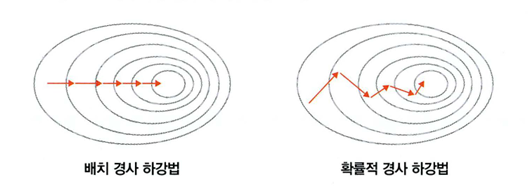

In [7]:
#class CustomDataset(Dataset):
#  def __init__(self):
#    self,x_data = [[1,2,3],[4,5,6],[7,8,9]]
#    slef.y_data = [[12],[18],[11]]
#    def __len__(self):
#      return len(self.x_data)
#    def __getitem__(self, idx):
#      x = torch..FloatTensor(self.x_data[idx])
#      y = torch.FloatTensor(self.y_data[idx])
#      return x,y
#dataset = CustomDataset()
#dataloader = DataLoader(
#    dataset,
#    batch_size=2,
#    shuffle=True,
#)

파이토치에서 아다그라드

```
optimizer = torch.optim.Adagrad(model.parameters(), lr=0.01)
```

아다델타
```
optimizer = torch.optim.Adadelta(model.parameters(),lr=1.0)
```

알엠에스프롭
```
optimizer = torch.optim.RMSprop(model.parameters(), lr=0.01)
```

모멘텀
```
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
```

네스테로프 모멘텀
```
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9, nesterov=True)
```

아담
```
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)


**4.2.4 딥러닝을 사용할 때 이점**

- 특성 추출
- 빅데이터의 효율적 활용



---

#4.3 딥러닝 알고리즘

**4.3.1 심층 신경망**


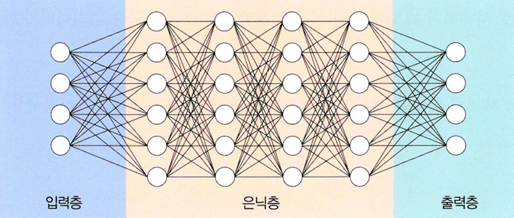

**4.3.2 합성곱 신경망**

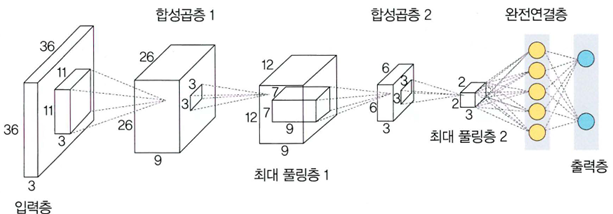

**4.3.3 순환 신경망**

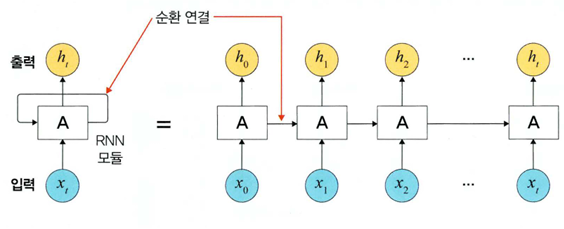

**4.3.4 제한된 볼츠만 머신**

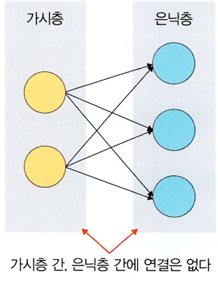

**4.3.5 심층 신뢰 신경망**

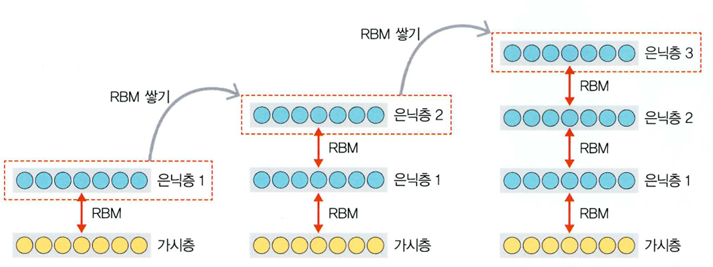